# Volatility Regime Classifier

This is the core piece for our research question: does calibration failure
depend on market volatility?

We classify each window as "low volatility" or "high volatility" using a
rolling standard deviation of returns, then later check if coverage and
conformal correction behave differently in each regime.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Load the full price series for both indices

In [2]:
sensex = pd.read_csv("../data/sensex_clean.csv", parse_dates=["Date"])
nifty = pd.read_csv("../data/nifty_clean.csv", parse_dates=["Date"])

sensex.shape, nifty.shape

((4054, 5), (4565, 5))

## Compute daily returns and rolling volatility

Returns = percent change day to day.
Rolling volatility = standard deviation of returns over the last 20 days
(about one trading month). This gives a smooth measure of how choppy the
market has been recently.

In [3]:
def add_volatility(df, window=20):
    df = df.copy()
    df["return"] = df["Close"].pct_change()
    df["volatility"] = df["return"].rolling(window).std()
    return df

sensex = add_volatility(sensex)
nifty = add_volatility(nifty)

sensex[["Date", "Close", "return", "volatility"]].tail()

,Date,Close,return,volatility
4049,2026-05-04,77269.40,0.004627,0.012480
4050,2026-05-05,77017.79,-0.003256,0.012554
4051,2026-05-06,77958.52,0.012214,0.012609
4052,2026-05-07,77844.52,-0.001462,0.012599
4053,2026-05-08,77328.19,-0.006633,0.009167


## Classify into low / high volatility regimes

Simple approach: split at the median. Anything above the median rolling
volatility is "high vol", anything below is "low vol".

In [4]:
def add_regime(df):
    df = df.copy()
    median_vol = df["volatility"].median()
    df["regime"] = np.where(df["volatility"] > median_vol, "high_vol", "low_vol")
    return df

sensex = add_regime(sensex)
nifty = add_regime(nifty)

sensex["regime"].value_counts()

regime
low_vol     2037
high_vol    2017
Name: count, dtype: int64

## Sanity check: plot price colored by regime

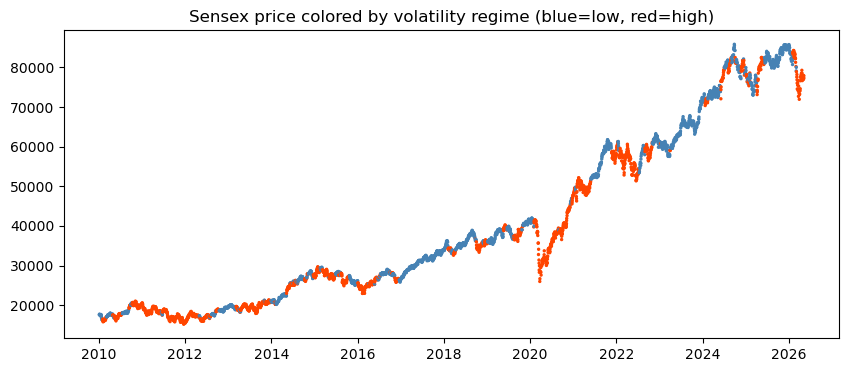

In [5]:
plt.figure(figsize=(10, 4))
colors = sensex["regime"].map({"low_vol": "steelblue", "high_vol": "orangered"})
plt.scatter(sensex["Date"], sensex["Close"], c=colors, s=2)
plt.title("Sensex price colored by volatility regime (blue=low, red=high)")
plt.show()

## Assign a regime label to each forecast window

We already have the date for each window (saved earlier as
sensex_window_dates.npy / nifty_window_dates.npy). For each window, we
look up what the volatility regime was at that date, and save that as a
label lined up with our existing forecasts/actuals arrays.

In [6]:
sensex_window_dates = np.load("sensex_window_dates.npy", allow_pickle=True)
nifty_window_dates = np.load("nifty_window_dates.npy", allow_pickle=True)

len(sensex_window_dates), len(nifty_window_dates)

(352, 403)

In [7]:
def get_regime_labels(df, window_dates):
    # build a quick lookup: date -> regime
    date_to_regime = dict(zip(df["Date"], df["regime"]))

    labels = []
    for d in window_dates:
        # d comes back as a pandas Timestamp already
        labels.append(date_to_regime.get(pd.Timestamp(d), "unknown"))
    return np.array(labels)

sensex_regime_labels = get_regime_labels(sensex, sensex_window_dates)
nifty_regime_labels = get_regime_labels(nifty, nifty_window_dates)

print(pd.Series(sensex_regime_labels).value_counts())
print(pd.Series(nifty_regime_labels).value_counts())

low_vol     197
high_vol    155
Name: count, dtype: int64
low_vol     223
high_vol    180
Name: count, dtype: int64


## Save the regime labels for use in the next notebook

In [8]:
np.save("sensex_regime_labels.npy", sensex_regime_labels)
np.save("nifty_regime_labels.npy", nifty_regime_labels)

print("saved")

saved
